In [1]:
import numpy as np
import pandas as pd
import pyagrum as gum
import pyagrum.lib.notebook as gnb
import pyagrum.lib.dynamicBN as gdyn

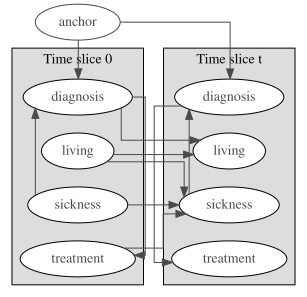

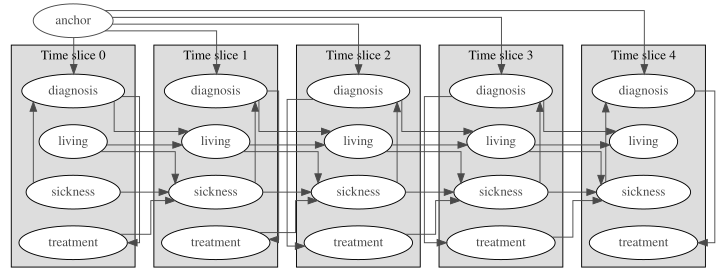

In [2]:
bn2 = gum.loadBN("elder_care_dbn/data/elder_twodbn.bif")
gdyn.showTimeSlices(bn2)

T = 5
dbn2 = gdyn.unroll2TBN(bn2, T)
gdyn.showTimeSlices(dbn2, size="10")

In [3]:
from cross_impact.model import build_network, UncertaintyFactor, CrossImpactNetwork
from cross_impact.pyagrum_import import marginals_and_joint_from_pyagrum
from cross_impact.pyagrum_export import graft_onto_pyagrum
from cross_impact.model import cross_impacts_from_joint

[0.67461952 0.27313861 0.00534759 0.04689428 0.        ]
[0.67731426 0.2729381  0.00490084 0.04403718 0.00080962]
[0.92269274 0.05015797 0.0189274  0.00822189]
[0.92309279 0.05021032 0.01859592 0.00810097]


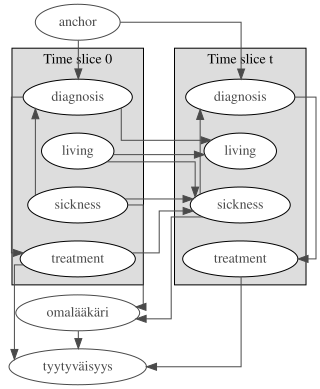

In [4]:
# extract from the learned BN
marginals, joint = marginals_and_joint_from_pyagrum(
    bn2, 
    ["sickness0", "sicknesst", "treatment0", "treatmentt",],
)

# Expert judgments
cross_impacts = {
    (0, 4): np.array([
        [1, 1],
        [1, 1],
        [1, 1], # should probably find some sort of balance between these
        [1, 1],
        [1, 1],
    ]),
    (1, 4): np.array([
        [1, 1],
        [1, 1],
        [1, 1],
        [1, 1],
        [1, 1],
    ]),
    (2, 5): np.array([
        [1,1,1],
        [1,1,1],
        [1,1,1],
        [1,1,1],
    ]),
    (3, 5):  np.array([
        [1,1,1],
        [1,1,1],
        [1,1,1],
        [1,1,1],
    ]),
    (4, 5): np.array([
        [1,0,-1], # no omalääkäri, satisfaction low
        [-1,0,1], # if omalääkäri, satisfaction high
    ]),
}

for marginal in marginals:
    print(marginal)

factors = [
    UncertaintyFactor("sickness0", 5, ()),
    UncertaintyFactor("sicknesst", 5, (0,)),
    UncertaintyFactor("treatment0", 4, ()),
    UncertaintyFactor("treatmentt", 4, (2,)),
    UncertaintyFactor("omalääkäri", 2, (0, 1,)),
    UncertaintyFactor("tyytyväisyys", 3, (2, 3, 4,)),
]
marginal_omalaakari = np.array([0.45, 0.55])
marginal_tyytyvaisyys = np.array([0.33, 0.33, 0.34])

# new bn
network = CrossImpactNetwork(
    factors=factors,
    marginals=[
        marginals[0], 
        marginals[1],
        marginals[2],
        marginals[3],
        marginal_omalaakari,
        marginal_tyytyvaisyys,
    ],
    cross_impacts=cross_impacts,
)

# attach new bn to old bn
built=build_network(network, mode="exact", initial_joint=joint)
merged=graft_onto_pyagrum(bn2, built, n_given=4)
gdyn.showTimeSlices(merged)

gnb.sideBySide(merged.cpt("omalääkäri"), merged.cpt("tyytyväisyys"))


In [5]:
T = 5
dmerged = gdyn.unroll2TBN(merged, T) # Is the issue here that we can't put these non-dbn nodes downstream?
gdyn.showTimeSlices(dmerged, size="10")

IndexError: Shape of '[[[0.44920691 0.55079309]
  [0.49486223 0.50513777]
  [0.47674272 0.52325728]
  [0.46858237 0.53141763]
  [0.5        0.5       ]]

 [[0.50184876 0.49815124]
  [0.44800453 0.55199547]
  [0.48404178 0.51595822]
  [0.46667479 0.53332521]
  [0.5        0.5       ]]

 [[0.50531468 0.49468532]
  [0.50313136 0.49686864]
  [0.44638364 0.55361636]
  [0.50174894 0.49825106]
  [0.5        0.5       ]]

 [[0.50933186 0.49066814]
  [0.50789873 0.49210127]
  [0.49846132 0.50153868]
  [0.4487016  0.5512984 ]
  [0.5        0.5       ]]

 [[0.48342798 0.51657202]
  [0.48592063 0.51407937]
  [0.4985857  0.5014143 ]
  [0.43865342 0.56134658]
  [0.5        0.5       ]]]' is not '(5, 5, 5, 5, 5, 2)'